# 16 — Do scoring leaps last? Backtesting the blip-or-real rule

**Question.** Notebook 12F set a rule, in advance, for whether Nickeil Alexander-Walker's 2025-26 leap was real (decision D33). Does that rule work on everyone else who made a big jump since 2000-01, and **who are its victims?**

**The rule (unchanged from D33).** Share of the leap kept = (points a game later − points the season before the leap) ÷ (points in the leap season − points the season before).
- **Real:** 80% or more kept. **Partly real:** 50–80%. **Blip:** under 50%.
- Judged at the **All-Star break of the season after the leap**, with at least 25 games played; otherwise no verdict.

**Who is tested.** Every leap season from 2000-01 to 2024-25, where the player played 20+ games the season before and 40+ in the leap season, and either:
- **got any MIP votes**, with a leap of 3+ points a game; or
- **jumped 5+ points a game**, voted for or not.

**What counts as a victim.** The rule is judged three ways:
1. **Called too early:** the verdict at the break differs from the verdict over the full season. This is the rule's own claim, that the break is early enough.
2. **Comebacks:** called a blip, but real again two seasons on.
3. **Late collapses:** called real, but a blip two seasons on.

Only (1) is a failure of the rule. (2) and (3) show the limits of a one-season horizon.

Voting is used only to choose who is tested; nothing is trained here.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.leaps import BLIP, REAL, leap_table
from unicorn.mip_history import load_games, voting
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, apply_style

warnings.filterwarnings("ignore")
apply_style()
games = load_games()
votes, winners = voting(games)
L = leap_table(games, votes, winners)
judged = L[L["verdict at the break"] != "no verdict"]
print(f"{len(L)} leaps, 2000-01 → 2024-25: {L['vote rank'].notna().sum()} got MIP votes, {int(L['winner'].sum())} won; "
      f"{len(judged)} have a verdict at the break")
L["verdict at the break"].value_counts()

609 leaps, 2000-01 → 2024-25: 406 got MIP votes, 25 won; 541 have a verdict at the break


verdict at the break
real           311
blip           130
partly real    100
no verdict      68
Name: count, dtype: int64

## 16A — Is the All-Star break early enough? ("called too early")

In [2]:
both = judged[judged["verdict next season"] != "no verdict"]
ORDER = ["blip", "partly real", "real"]
print(f"verdict at the break = verdict over the full season in {(both['verdict at the break'] == both['verdict next season']).sum()} "
      f"of {len(both)} ({(both['verdict at the break'] == both['verdict next season']).mean():.0%})")
early = both[both["verdict at the break"] != both["verdict next season"]]
near = np.minimum((early["kept at the break"] - BLIP).abs(), (early["kept at the break"] - REAL).abs()) < 0.10
print(f"of the {len(early)} called too early, {near.sum()} ({near.mean():.0%}) were within 10 points of a line at the break")
display(pd.crosstab(both["verdict at the break"], both["verdict next season"]).reindex(index=ORDER, columns=ORDER)
        .rename_axis(index="at the break", columns="over the full season"))
SHOW = ["season", "player", "vote rank", "points before", "points in the leap", "kept at the break", "games by the break",
        "kept next season", "kept two seasons on", "verdict at the break", "verdict next season", "verdict two seasons on"]
FMT = {c: "{:.0%}" for c in ["kept at the break", "kept next season", "kept two seasons on"]}
flips = early[(early["verdict at the break"].map(ORDER.index) - early["verdict next season"].map(ORDER.index)).abs() == 2]
print("the big flips (blip ↔ real):")
flips[SHOW].style.format(FMT, precision=1).hide(axis="index")

verdict at the break = verdict over the full season in 466 of 541 (86%)
of the 75 called too early, 54 (72%) were within 10 points of a line at the break


over the full season,blip,partly real,real
at the break,,,
blip,111,15,4
partly real,14,66,20
real,0,22,289


the big flips (blip ↔ real):


season,player,vote rank,points before,points in the leap,kept at the break,games by the break,kept next season,kept two seasons on,verdict at the break,verdict next season,verdict two seasons on
2006-07,Hakim Warrick,nan,4.1,12.7,49%,45.0,84%,87%,blip,real,real
2006-07,JR Smith,nan,7.7,13.0,41%,44.0,86%,142%,blip,real,real
2011-12,Ersan Ilyasova,2.0,9.5,13.0,48%,49.0,104%,49%,blip,real,blip
2019-20,Miles Bridges,nan,7.5,13.0,47%,35.0,96%,231%,blip,real,real


In [3]:
print("MIP winners called too early:")
early[early["winner"]][SHOW].style.format(FMT, precision=1).hide(axis="index")

MIP winners called too early:


season,player,vote rank,points before,points in the leap,kept at the break,games by the break,kept next season,kept two seasons on,verdict at the break,verdict next season,verdict two seasons on
2000-01,Tracy McGrady,1.0,15.4,26.8,78%,46.0,90%,146%,partly real,real,real
2008-09,Danny Granger,1.0,19.6,25.8,45%,35.0,73%,15%,blip,partly real,blip


### 16A findings

- **The break is early enough for about 6 verdicts in 7.** Over 541 judged leaps, the verdict at the break matched the full season 86% of the time.
- **Most misses are near-misses.** 72% of the leaps called too early were within 10 points of the 50% or 80% line at the break. They moved one band, never two the wrong way.
- **"Real" at the break never became a "blip" by season end.** The reverse happened 4 times: JR Smith and Hakim Warrick (2006-07 leaps), Ersan Ilyasova (2011-12) and Miles Bridges (2019-20). Each sat just under 50% at the break and finished the season strong.
- **Two MIP winners were called too early:** Tracy McGrady (78% at the break, 90% by season end) and Danny Granger (45% at the break, 35 games, 73% by season end).

## 16B — The victims: comebacks and late collapses (two seasons on)

In [4]:
two = judged[judged["verdict two seasons on"] != "no verdict"]
display(pd.crosstab(two["verdict at the break"], two["verdict two seasons on"]).reindex(index=ORDER, columns=ORDER)
        .rename_axis(index="at the break", columns="two seasons on"))
comebacks = two[(two["verdict at the break"] == "blip") & (two["verdict two seasons on"] == "real")]
collapses = two[(two["verdict at the break"] == "real") & (two["verdict two seasons on"] == "blip")]
blips, reals = two[two["verdict at the break"] == "blip"], two[two["verdict at the break"] == "real"]
print(f"comebacks: {len(comebacks)} of {len(blips)} blips ({len(comebacks) / len(blips):.0%}); "
      f"late collapses: {len(collapses)} of {len(reals)} reals ({len(collapses) / len(reals):.0%})")
print("comebacks who got MIP votes:")
comebacks[comebacks["vote rank"].notna()].sort_values("vote rank")[SHOW].style.format(FMT, precision=1).hide(axis="index")

two seasons on,blip,partly real,real
at the break,,,
blip,77,11,25
partly real,38,13,35
real,48,39,200


comebacks: 25 of 113 blips (22%); late collapses: 48 of 287 reals (17%)
comebacks who got MIP votes:


season,player,vote rank,points before,points in the leap,kept at the break,games by the break,kept next season,kept two seasons on,verdict at the break,verdict next season,verdict two seasons on
2020-21,Julius Randle,1.0,19.5,24.1,7%,57.0,13%,122%,blip,blip,real
2013-14,DeMar DeRozan,8.0,18.1,22.7,5%,32.0,43%,117%,blip,blip,real
2010-11,Wesley Matthews,8.0,9.4,15.9,48%,34.0,67%,84%,blip,partly real,real
2013-14,Isaiah Thomas,10.0,13.9,20.3,20%,46.0,39%,129%,blip,blip,real
2020-21,Jordan Clarkson,10.0,15.2,18.4,9%,55.0,26%,176%,blip,blip,real
2023-24,Grayson Allen,10.0,10.4,13.5,20%,43.0,7%,196%,blip,blip,real
2001-02,Hedo Turkoglu,12.0,5.3,10.1,48%,41.0,29%,82%,blip,blip,real
2001-02,Kenny Thomas,12.0,7.1,14.1,31%,37.0,43%,93%,blip,blip,real
2004-05,Udonis Haslem,12.0,7.3,10.9,49%,52.0,57%,95%,blip,partly real,real
2009-10,David Lee,17.0,16.0,20.2,-2%,46.0,12%,97%,blip,blip,real


In [5]:
print("comebacks with no MIP votes (5+ point leaps):")
comebacks[comebacks["vote rank"].isna()].sort_values("season")[SHOW].style.format(FMT, precision=1).hide(axis="index")

comebacks with no MIP votes (5+ point leaps):


season,player,vote rank,points before,points in the leap,kept at the break,games by the break,kept next season,kept two seasons on,verdict at the break,verdict next season,verdict two seasons on
2001-02,Quentin Richardson,nan,8.1,13.3,27%,37.0,25%,176%,blip,blip,real
2003-04,DeShawn Stevenson,nan,4.6,11.4,-6%,30.0,48%,94%,blip,blip,real
2004-05,Chucky Atkins,nan,8.4,13.6,-14%,41.0,22%,92%,blip,blip,real
2006-07,Hakim Warrick,nan,4.1,12.7,49%,45.0,84%,87%,blip,real,real
2006-07,JR Smith,nan,7.7,13.0,41%,44.0,86%,142%,blip,real,real
2010-11,Glen Davis,nan,6.3,11.7,19%,32.0,55%,161%,blip,partly real,real
2010-11,Ramon Sessions,nan,8.2,13.3,42%,31.0,60%,122%,blip,partly real,real
2014-15,Russell Westbrook,nan,21.8,28.1,36%,54.0,27%,154%,blip,blip,real
2016-17,Karl-Anthony Towns,nan,18.3,25.1,28%,61.0,43%,89%,blip,blip,real
2017-18,Khris Middleton,nan,14.7,20.1,44%,54.0,66%,114%,blip,partly real,real


In [6]:
print("late collapses who got MIP votes (top 10 by vote rank):")
collapses[collapses["vote rank"].notna()].sort_values("vote rank").head(10)[SHOW].style.format(FMT, precision=1).hide(axis="index")

late collapses who got MIP votes (top 10 by vote rank):


season,player,vote rank,points before,points in the leap,kept at the break,games by the break,kept next season,kept two seasons on,verdict at the break,verdict next season,verdict two seasons on
2005-06,Nenad Krstic,3.0,10.0,13.5,181%,26.0,181%,-94%,real,real,blip
2021-22,Darius Garland,3.0,17.4,21.7,102%,51.0,98%,14%,real,real,blip
2018-19,Buddy Hield,4.0,13.5,20.7,96%,54.0,79%,43%,real,partly real,blip
2007-08,Al Jefferson,4.0,16.0,21.0,141%,50.0,141%,21%,real,real,blip
2022-23,Nic Claxton,5.0,8.7,12.6,88%,44.0,80%,41%,real,partly real,blip
2015-16,Jae Crowder,6.0,7.7,14.2,94%,47.0,95%,31%,real,real,blip
2001-02,Troy Hudson,7.0,4.8,11.7,135%,46.0,136%,40%,real,real,blip
2006-07,Luol Deng,7.0,14.3,18.8,81%,33.0,60%,-4%,real,partly real,blip
2018-19,Montrezl Harrell,7.0,11.0,16.6,140%,54.0,136%,45%,real,real,blip
2007-08,Chris Paul,8.0,17.2,21.1,107%,46.0,147%,38%,real,real,blip


In [7]:
nv = L[L["verdict at the break"] == "no verdict"]
print(f"no verdict: {len(nv)} leaps ({nv['games by the break'].isna().sum()} did not play before the next break at all)")
nv[nv["vote rank"] <= 5].sort_values("season")[SHOW].style.format(FMT, precision=1).hide(axis="index")

no verdict: 68 leaps (18 did not play before the next break at all)


season,player,vote rank,points before,points in the leap,kept at the break,games by the break,kept next season,kept two seasons on,verdict at the break,verdict next season,verdict two seasons on
2002-03,Gilbert Arenas,1.0,10.9,18.3,96%,24.0,118%,198%,no verdict,real,real
2002-03,Troy Murphy,3.0,5.9,11.7,29%,11.0,71%,163%,no verdict,partly real,real
2004-05,Dan Dickau,5.0,2.2,12.5,10%,19.0,10%,11%,no verdict,no verdict,blip
2005-06,David West,2.0,6.2,17.1,93%,23.0,111%,132%,no verdict,real,real
2011-12,Andrew Bynum,4.0,11.3,18.7,nan%,nan,nan%,-36%,no verdict,no verdict,blip
2012-13,Larry Sanders,3.0,3.6,9.8,67%,23.0,67%,59%,no verdict,no verdict,partly real
2016-17,Isaiah Thomas,5.0,22.2,28.9,-122%,18.0,-105%,-211%,no verdict,blip,no verdict
2020-21,Michael Porter Jr.,3.0,9.3,19.0,6%,9.0,6%,83%,no verdict,no verdict,real
2024-25,Christian Braun,4.0,7.3,15.4,32%,19.0,57%,nan%,no verdict,partly real,no verdict


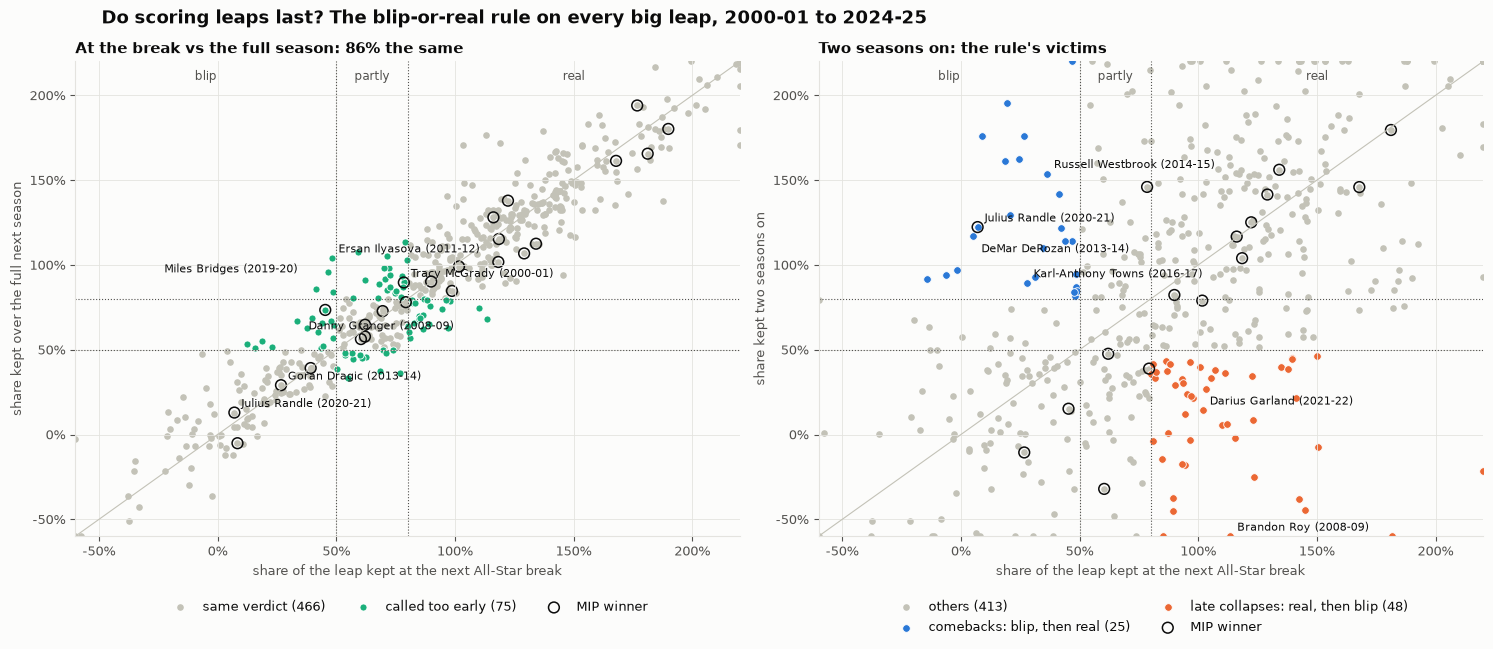

In [8]:
# chart: the rule at the break against (left) the full season and (right) two seasons on
LIM = (-0.6, 2.2)
def frame(ax, xlabel, ylabel, title):
    for v in (BLIP, REAL):
        ax.axvline(v, color=INK2, linewidth=0.8, linestyle=":"); ax.axhline(v, color=INK2, linewidth=0.8, linestyle=":")
    ax.plot(LIM, LIM, color=MUTED, linewidth=0.8)
    ax.set_xlim(*LIM); ax.set_ylim(*LIM)
    pct = lambda v, _: f"{v:.0%}"
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title, loc="left", fontsize=11)
    for x, lab in [((LIM[0] + BLIP) / 2, "blip"), ((BLIP + REAL) / 2, "partly"), ((REAL + LIM[1]) / 2, "real")]:
        ax.text(x, LIM[1] - 0.05, lab, ha="center", va="top", fontsize=8.5, color=INK2)
NUDGE = {("DeMar DeRozan", "2013-14"): (6, -12), ("Miles Bridges", "2019-20"): (-118, 0), ("Danny Granger", "2008-09"): (-12, -14)}
def label(ax, d, xcol, ycol, picks):
    """Label chosen leaps, given as (player, leap season)."""
    for _, r in d[[(p, s) in picks for p, s in zip(d["player"], d["season"])]].iterrows():
        x, y = np.clip(r[xcol], *LIM), np.clip(r[ycol], *LIM)
        ax.annotate(f"{r['player']} ({r['season'][:4]}-{r['season'][5:]})", (x, y), xytext=NUDGE.get((r["player"], r["season"]), (5, 4)), textcoords="offset points", fontsize=8, color=INK)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6.6))
clip = lambda s: s.clip(*LIM)
ok = both[both["verdict at the break"] == both["verdict next season"]]
a1.scatter(clip(ok["kept at the break"]), clip(ok["kept next season"]), s=14, color=MUTED, label=f"same verdict ({len(ok)})")
a1.scatter(clip(early["kept at the break"]), clip(early["kept next season"]), s=26, color=SERIES[2], edgecolor="white", linewidth=0.6,
           label=f"called too early ({len(early)})")
w = both[both["winner"]]
a1.scatter(clip(w["kept at the break"]), clip(w["kept next season"]), s=60, facecolor="none", edgecolor=INK, linewidth=1.1, label="MIP winner")
label(a1, both, "kept at the break", "kept next season", [("Miles Bridges", "2019-20"), ("Ersan Ilyasova", "2011-12"), ("Danny Granger", "2008-09"),
                                                         ("Tracy McGrady", "2000-01"), ("Julius Randle", "2020-21"), ("Goran Dragic", "2013-14")])
frame(a1, "share of the leap kept at the next All-Star break", "share kept over the full next season", "At the break vs the full season: 86% the same")
a1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=9)

rest = two.drop(comebacks.index).drop(collapses.index)
a2.scatter(clip(rest["kept at the break"]), clip(rest["kept two seasons on"]), s=14, color=MUTED, label=f"others ({len(rest)})")
a2.scatter(clip(comebacks["kept at the break"]), clip(comebacks["kept two seasons on"]), s=30, color=BLUE, edgecolor="white", linewidth=0.6,
           label=f"comebacks: blip, then real ({len(comebacks)})")
a2.scatter(clip(collapses["kept at the break"]), clip(collapses["kept two seasons on"]), s=30, color=ORANGE, edgecolor="white", linewidth=0.6,
           label=f"late collapses: real, then blip ({len(collapses)})")
w2 = two[two["winner"]]
a2.scatter(clip(w2["kept at the break"]), clip(w2["kept two seasons on"]), s=60, facecolor="none", edgecolor=INK, linewidth=1.1, label="MIP winner")
label(a2, two, "kept at the break", "kept two seasons on",
      [("Julius Randle", "2020-21"), ("DeMar DeRozan", "2013-14"), ("Karl-Anthony Towns", "2016-17"),
       ("Russell Westbrook", "2014-15"), ("Brandon Roy", "2008-09"), ("Darius Garland", "2021-22")])
frame(a2, "share of the leap kept at the next All-Star break", "share kept two seasons on", "Two seasons on: the rule's victims")
a2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=9)
fig.suptitle("Do scoring leaps last? The blip-or-real rule on every big leap, 2000-01 to 2024-25", x=0.07, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "16_leap_rule_backtest.png", dpi=150, bbox_inches="tight")

### 16B findings

- **About 1 blip in 5 comes back.** 25 leaps called blips at the break were real again two seasons on.
  - **The famous one is Julius Randle,** the 2020-21 winner: 7% kept at the next break, 122% two seasons on (All-NBA in 2022-23).
  - DeMar DeRozan (2013-14 leap), Isaiah Thomas (2013-14) and Karl-Anthony Towns (2016-17) also got MIP votes, fell back the next season, then went past their leap.
  - **A star's return is a common story,** the mirror of D29's "star left". Russell Westbrook's 2014-15 leap came with Kevin Durant injured; Durant came back and Westbrook's scoring fell, then rose again after Durant left in 2016.
- **About 1 real in 6 collapses later.** 48 leaps called real were blips two seasons on.
  - These are mostly injuries and age: Brandon Roy's knees, Isaiah Thomas's hip (2015-16 leap), Darius Garland, Chris Paul's 2009-10 injury.
  - The rule only looks one season ahead, so it can't see these.
- **No verdict is mostly injury:** 68 leaps had fewer than 25 games by the next break. Among high vote-getters: Gilbert Arenas, David West, Michael Porter Jr.
- **For Alexander-Walker:** a verdict of "real" at the break says his leap survived the next season, not that it is permanent. A "blip" could still be a Randle.

## 16C — Can points per 36 minutes spot the comebacks?

D33 shows points per 36 minutes next to the verdict but doesn't use it. Is it worth more? Among blips, did those who kept their scoring **rate** (fewer minutes, not worse scoring) come back more often?

In [9]:
b = two[two["verdict at the break"] == "blip"].copy()
b["came back"] = b["verdict two seasons on"].isin(["real", "partly real"])
b["per 36 at the break vs the leap"] = pd.cut(b["per 36 kept at the break"], [0, 0.85, 0.95, 3], labels=["fell 15%+", "fell 5–15%", "within 5%"])
b.groupby("per 36 at the break vs the leap", observed=True)["came back"].agg(**{"blips": "size", "came back (partly or fully)": "mean"}).style.format({"came back (partly or fully)": "{:.0%}"})

,blips,came back (partly or fully)
per 36 at the break vs the leap,,
fell 15%+,55,27%
fell 5–15%,40,32%
within 5%,18,44%


### 16C findings

- **A weak hint, not a rule.** Blips who kept their scoring rate per 36 minutes came back (partly or fully) 44% of the time, against 27% for those whose rate fell 15% or more.
- **But that rests on 18 players,** so per 36 stays a fact shown next to the verdict, as D33 says. Changing the rule now, after looking at the answers, would break the point of writing it down in advance.

## What this means

- **The rule does what it claims.** At the break it predicts the full next season correctly about 6 times in 7, and the misses are near the lines.
- **It answers "did the leap survive the next season?", not "is it permanent?".** About 1 blip in 5 comes back and about 1 real in 6 collapses later.
- **It isn't specific to Alexander-Walker.** It works the same way for any leap, so it could carry a general name (see the README).